In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip "/content/drive/MyDrive/!BinusMaterials/Sem 7/UTS ASP/Problem 1/Dataset1 dogcat audio.zip" -d "/content/extracted_data"

Archive:  /content/drive/MyDrive/!BinusMaterials/Sem 7/UTS ASP/Problem 1/Dataset1 dogcat audio.zip
  inflating: /content/extracted_data/cats_dogs/cat_1.wav  
  inflating: /content/extracted_data/cats_dogs/cat_10.wav  
  inflating: /content/extracted_data/cats_dogs/cat_100.wav  
  inflating: /content/extracted_data/cats_dogs/cat_101.wav  
  inflating: /content/extracted_data/cats_dogs/cat_102.wav  
  inflating: /content/extracted_data/cats_dogs/cat_103.wav  
  inflating: /content/extracted_data/cats_dogs/cat_105.wav  
  inflating: /content/extracted_data/cats_dogs/cat_106.wav  
  inflating: /content/extracted_data/cats_dogs/cat_107.wav  
  inflating: /content/extracted_data/cats_dogs/cat_108.wav  
  inflating: /content/extracted_data/cats_dogs/cat_109.wav  
  inflating: /content/extracted_data/cats_dogs/cat_11.wav  
  inflating: /content/extracted_data/cats_dogs/cat_110.wav  
  inflating: /content/extracted_data/cats_dogs/cat_112.wav  
  inflating: /content/extracted_data/cats_dogs/cat_

In [3]:
import numpy as np  # linear algebra
import pandas as pd  # CSV file
import scipy.io.wavfile as sci_wav  # Open wav files
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
import librosa

# Load Dataset

In [4]:
ROOT_DIR = '/content/extracted_data/cats_dogs'
CSV_PATH = '/content/extracted_data/train_test_split.csv'

In [5]:
train_test = pd.read_csv(CSV_PATH)

In [6]:
def load_dataset(train_test_df = train_test, root_dir=ROOT_DIR):
    data = []

    for fname in train_test_df['train_cat'].dropna():
        data.append({
            'file_path': root_dir + '/' + fname,
            'class_name': 'cat',
            'label': 0,
            'split': 'train'
        })

    for fname in train_test_df['train_dog'].dropna():
        data.append({
            'file_path': root_dir + '/' + fname,
            'class_name': 'dog',
            'label': 1,
            'split': 'train'
        })

    for fname in train_test_df['test_cat'].dropna():
        data.append({
            'file_path': root_dir + '/' + fname,
            'class_name': 'cat',
            'label': 0,
            'split': 'test'
        })

    for fname in train_test_df['test_dog'].dropna():
        data.append({
            'file_path': root_dir + '/' + fname,
            'class_name': 'dog',
            'label': 1,
            'split': 'test'
        })

    return pd.DataFrame(data)

In [7]:
meta = load_dataset()

# Basic Exploratory Data Analysis: Only duration, waveform, spectrum, stft spectogram, mel spectogram

# **Jawaban No a**

# Kesimpulan
1.	Durasi audio kucing sedikit lebih panjang
2.	Dari data waveform, tidak terdapat pola yang terlihat.
3.	Dari data magnitude, terlihat bahwa terdapat frekuensi yang memiliki puncak yang tajam dan berdempetan.
4.	Dari data STFT spectrogram, untuk melihat struktur harmonik suara, terlihat bahwa STFT spectrogram anjing memiliki pola seperti lapisan garis horizontal.
5.	Dari data Mel spectrogram, untuk melihat struktur harmonik suara yang sudah diadaptasikan ke range pendengaran manusia, terlihat bahwa Mel spectrogram anjing memiliki pola seperti lapisan garis horizontal.

Alasan menggunakan pendekatan tersebut:
1. Durasi audio perlu dicek untuk mengetahui apakah durasinya seragam atau tidak, bagaimana persebarannya.
2. Waveform digunakan untuk melihat amplitudo dan juga melihat apakah ada lonjakan sinyal audio misalnya gonggongan anjing yang garing (crisp)
3. Magnitude untuk melihat puncak frekuensi yang dominan.
4. STFT spectrogram untuk melihat struktur harmonik suara.
5. Mel spectrogram untuk melihat struktur harmonik suara yang sudah diadaptasikan ke range pendengaran manusia.

In [8]:
meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   file_path   277 non-null    object
 1   class_name  277 non-null    object
 2   label       277 non-null    int64 
 3   split       277 non-null    object
dtypes: int64(1), object(3)
memory usage: 8.8+ KB


In [9]:
print(meta.value_counts(['split', 'class_name']))

split  class_name
train  cat           115
       dog            64
test   dog            49
       cat            49
Name: count, dtype: int64


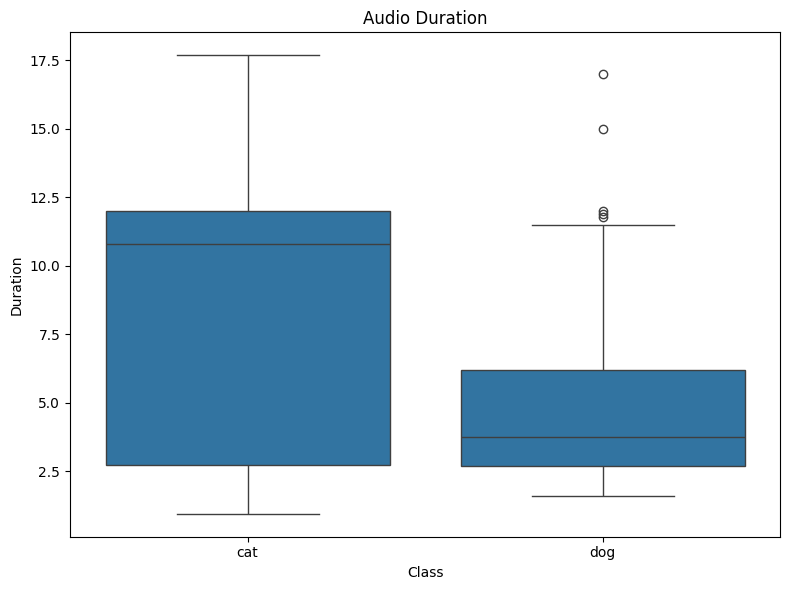

In [10]:
train_df = meta[meta['split'] == 'train'].copy()

durations = []
for file_path in train_df['file_path']:
    y, sr = librosa.load(file_path, sr=None)
    durations.append(librosa.get_duration(y=y, sr=sr))

train_df['duration_sec'] = durations

plt.figure(figsize=(8, 6))
sns.boxplot(data=train_df, x='class_name', y='duration_sec')

plt.title('Audio Duration')
plt.xlabel('Class')
plt.ylabel('Duration')
plt.tight_layout()
plt.show()

In [11]:
train_cats = meta[(meta['class_name'] == 'cat') & (meta['split'] == 'train')].head(4)
train_dogs = meta[(meta['class_name'] == 'dog') & (meta['split'] == 'train')].head(4)

cat_audios = [librosa.load(row['file_path'], sr=16000) for _, row in train_cats.iterrows()]
dog_audios = [librosa.load(row['file_path'], sr=16000) for _, row in train_dogs.iterrows()]

In [12]:
import IPython.display as ipd

cat_file = train_cats.iloc[0]['file_path']
dog_file = train_dogs.iloc[0]['file_path']

print("Cat audio:")
display(ipd.Audio(cat_file))

print("Dog audio:")
display(ipd.Audio(dog_file))

Cat audio:


Dog audio:


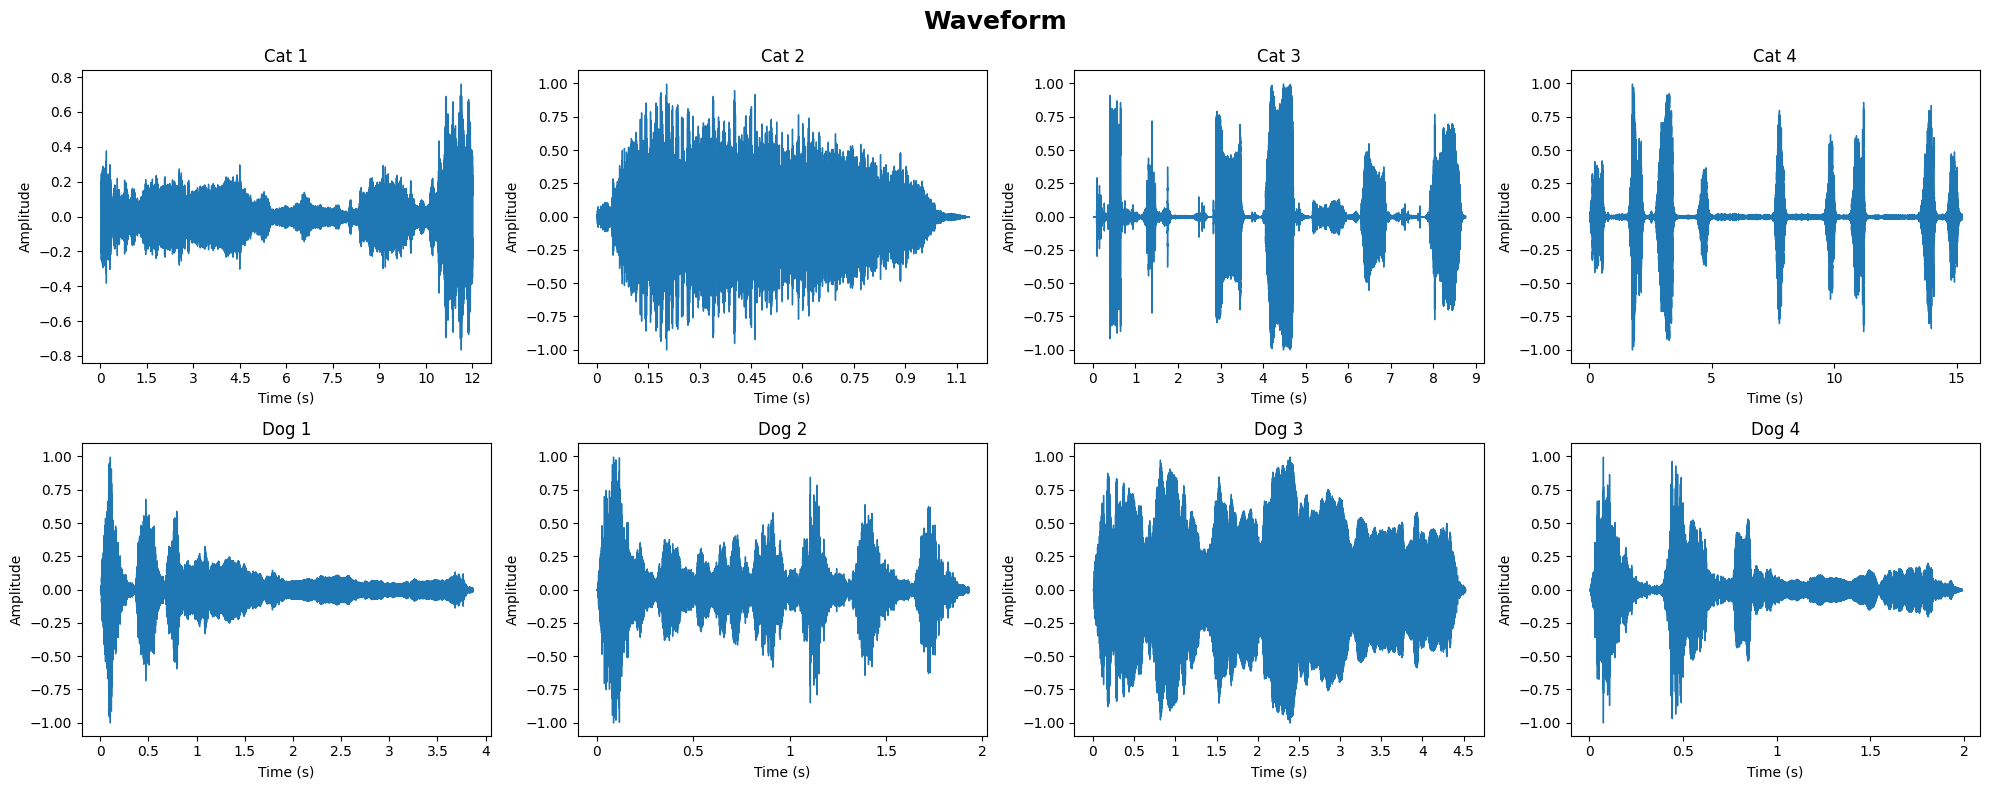

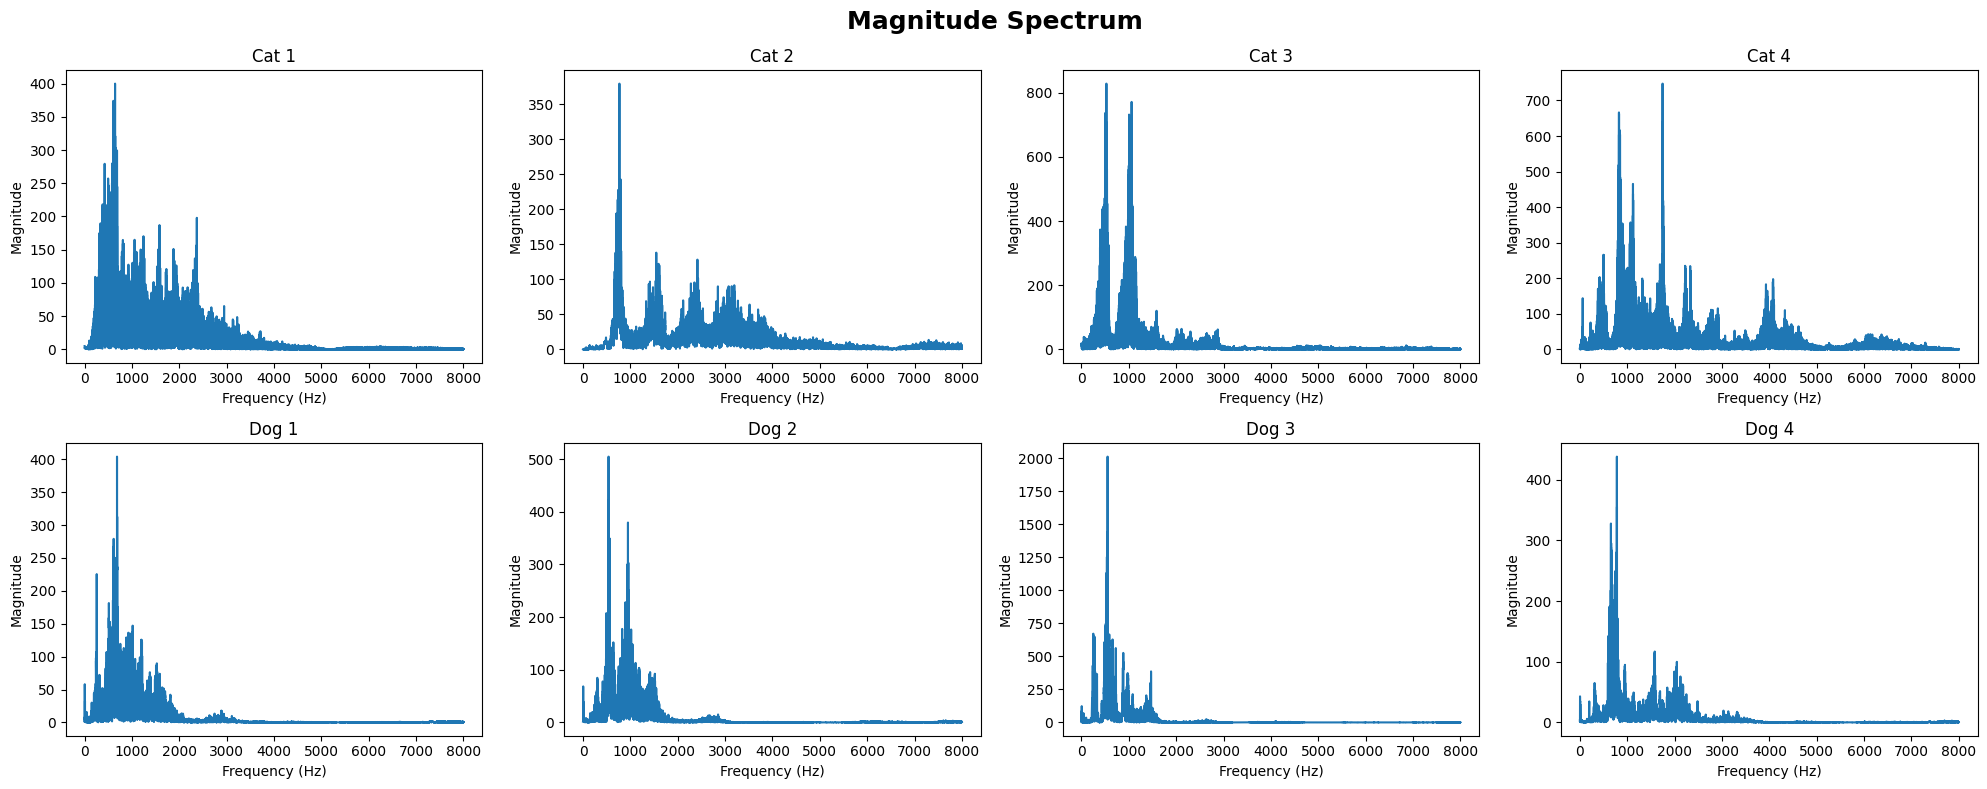

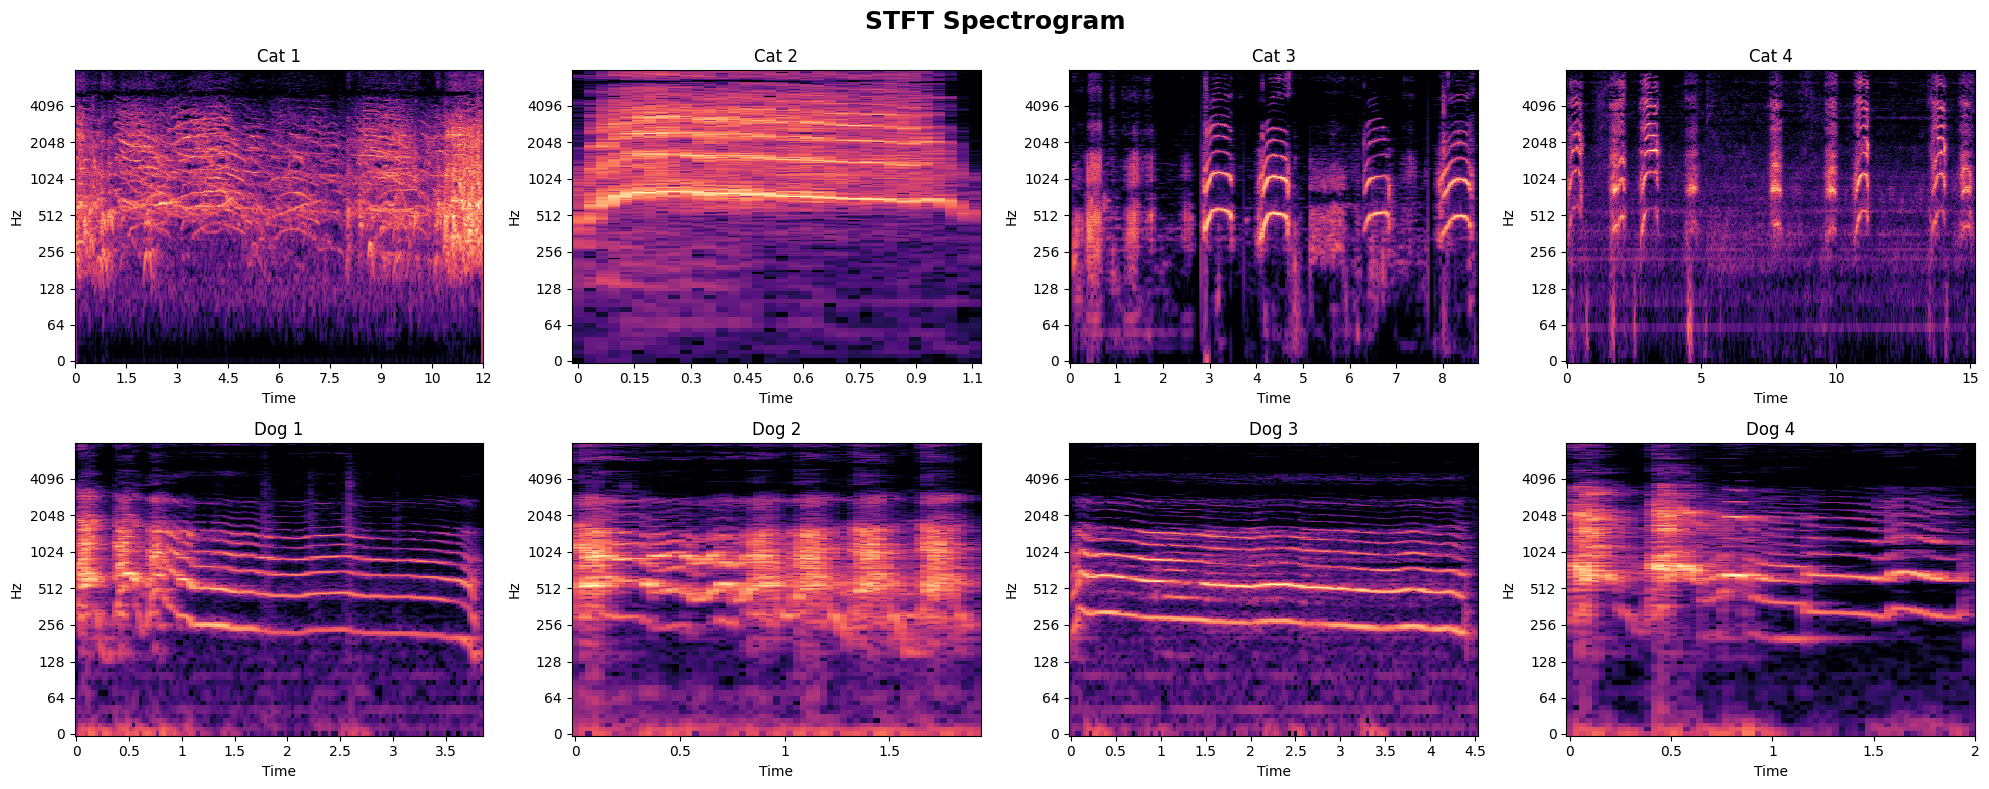

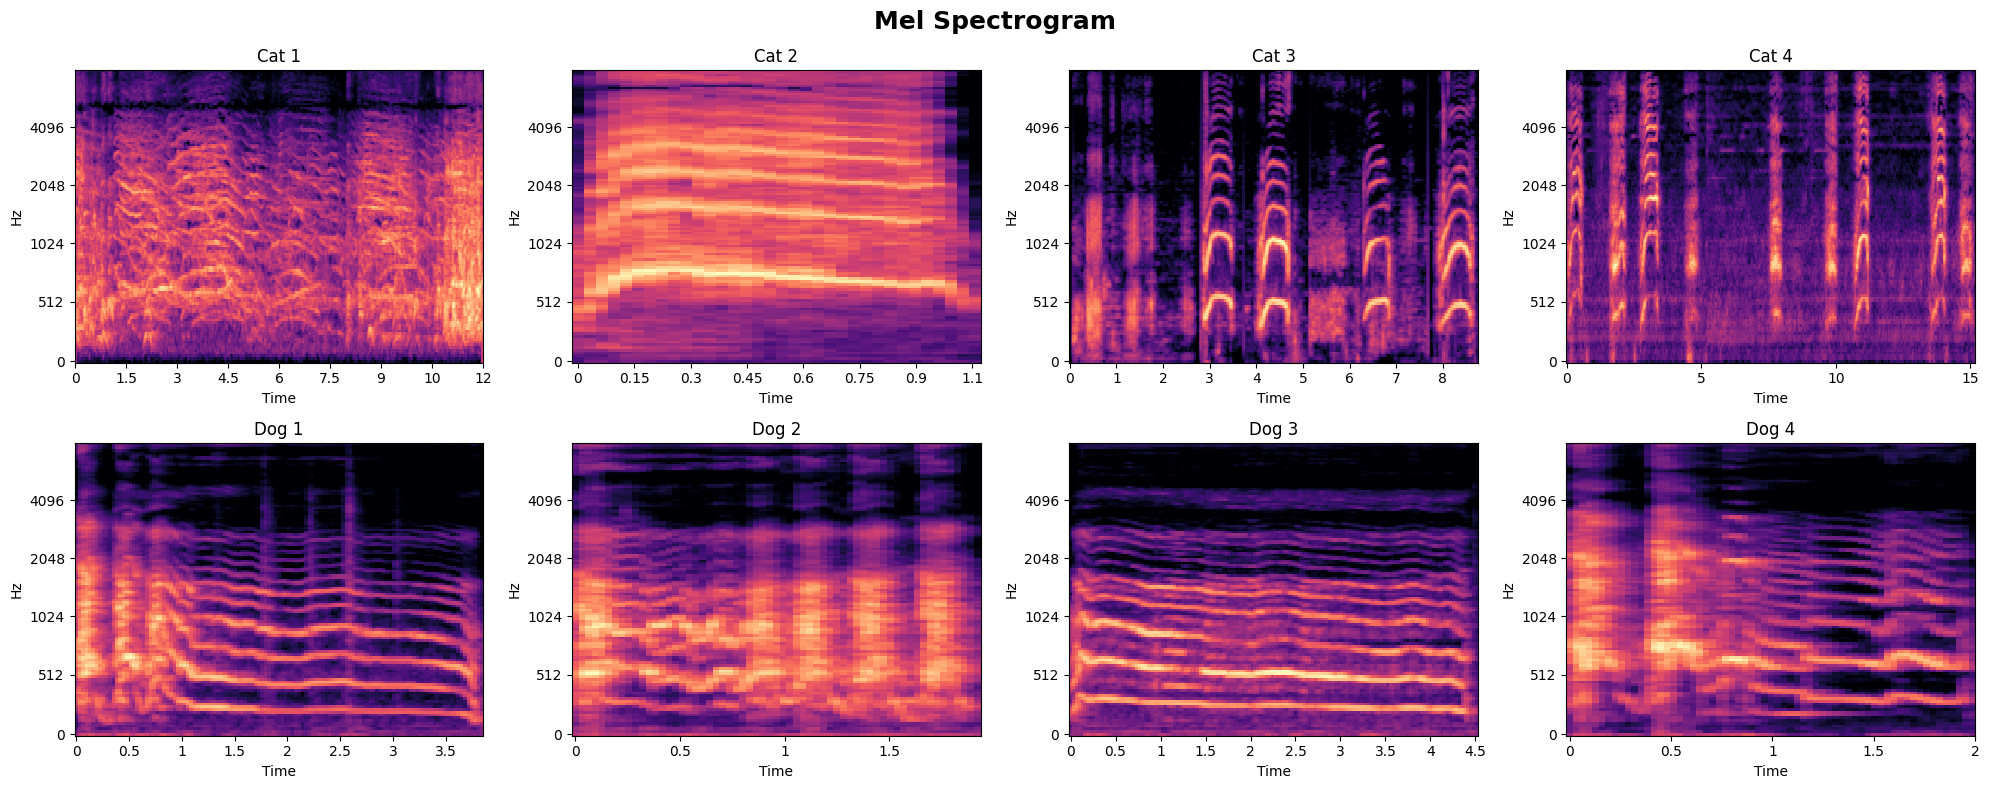

In [13]:
def plot_waveform(y, sr, ax, title):
    librosa.display.waveshow(y, sr=sr, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')

def plot_magnitude_spectrum(y, sr, ax, title):
    fft = np.fft.fft(y)
    magnitude = np.abs(fft)
    frequency = np.linspace(0, sr, len(magnitude))
    half_freq = frequency[:int(len(frequency)/2)]
    half_mag = magnitude[:int(len(magnitude)/2)]
    ax.plot(half_freq, half_mag)
    ax.set_title(title)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Magnitude')

def plot_stft_spectrogram(y, sr, ax, title):
    stft = librosa.stft(y)
    stft_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
    librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='log', ax=ax)
    ax.set_title(title)

def plot_mel_spectrogram(y, sr, ax, title):
    mel = librosa.feature.melspectrogram(y=y, sr=sr)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    librosa.display.specshow(mel_db, sr=sr, x_axis='time', y_axis='mel', ax=ax)
    ax.set_title(title)

plots = [
    (plot_waveform, "Waveform"),
    (plot_magnitude_spectrum, "Magnitude Spectrum"),
    (plot_stft_spectrogram, "STFT Spectrogram"),
    (plot_mel_spectrogram, "Mel Spectrogram")
]

for plot_func, figure_title in plots:
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
    fig.suptitle(figure_title, fontsize=18, fontweight='bold')

    for i in range(4):
        y, sr = cat_audios[i]
        plot_func(y, sr, axes[0, i], f"Cat {i+1}")

    for i in range(4):
        y, sr = dog_audios[i]
        plot_func(y, sr, axes[1, i], f"Dog {i+1}")

    plt.tight_layout()
    plt.show()

# 2. Feature Extraction and Further EDA

# **Jawaban No B**

Dilakukan feature extraction secara exhaustive (referensi exhaustive adalah semua fitur yg digunakan pada ipynb esc50 yang diberikan oleh Pak Alex).

In [14]:
TARGET_SR = 16000
N_FFT = 2048
HOP_LENGTH = 512
N_MFCC = 15

In [15]:
from scipy.stats import skew, kurtosis

def load_audio(file_path, sr=TARGET_SR):
    y, sr = librosa.load(
        file_path,
        sr=sr,
        mono=True,
    )
    return y.astype(np.float32), sr

def summarize(arr, prefix):
    arr = np.asarray(arr, dtype=float).ravel()
    arr = arr[np.isfinite(arr)]

    if len(arr) == 0:
        return {
            f"{prefix}_mean": 0.0,
            f"{prefix}_std": 0.0,
            f"{prefix}_min": 0.0,
            f"{prefix}_max": 0.0,
        }

    return {
        f"{prefix}_mean": float(np.mean(arr)),
        f"{prefix}_std": float(np.std(arr)),
        f"{prefix}_min": float(np.min(arr)),
        f"{prefix}_max": float(np.max(arr)),
    }


def extract_time_features(y, sr):
    feats = {}

    rms = librosa.feature.rms(
        y=y,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH
    )[0]
    feats.update(summarize(rms, "rms"))

    zcr = librosa.feature.zero_crossing_rate(
        y,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH
    )[0]
    feats.update(summarize(zcr, "zcr"))

    peak = float(np.max(np.abs(y)))
    global_rms = float(np.sqrt(np.mean(y**2)) + 1e-12)

    feats["peak_amplitude"] = peak
    feats["crest_factor"] = peak / global_rms

    frames = librosa.util.frame(
        y,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH
    )
    ste = np.mean(frames**2, axis=0)
    feats.update(summarize(ste, "ste"))

    envelope = np.abs(y)
    feats["envelope_mean"] = float(np.mean(envelope))
    feats["envelope_std"] = float(np.std(envelope))

    feats["amplitude_skewness"] = float(skew(y))
    feats["amplitude_kurtosis"] = float(kurtosis(y))

    return feats

In [16]:
def spectral_flux(S):
    S = np.asarray(S, dtype=float)
    denom = np.linalg.norm(S, axis=0, keepdims=True) + 1e-12
    S_norm = S / denom

    diff = np.diff(S_norm, axis=1)
    flux = np.sqrt(np.sum(diff**2, axis=0))

    if len(flux):
        flux = np.concatenate([[0.0], flux])

    return flux

def spectral_entropy(S):
    power = S**2
    p = power / (np.sum(power, axis=0, keepdims=True) + 1e-12)
    ent = -np.sum(p * np.log2(p + 1e-12), axis=0)
    ent /= np.log2(S.shape[0])
    return ent

def extract_spectral_features(y, sr):
    feats = {}
    S = np.abs(
        librosa.stft(
            y,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH
        )
    )

    centroid = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(
        S=S, sr=sr, roll_percent=0.85
    )[0]
    flatness = librosa.feature.spectral_flatness(S=S)[0]
    flux = spectral_flux(S)
    entropy = spectral_entropy(S)

    feats.update(summarize(centroid, "spectral_centroid"))
    feats.update(summarize(bandwidth, "spectral_bandwidth"))
    feats.update(summarize(rolloff, "spectral_rolloff"))
    feats.update(summarize(flatness, "spectral_flatness"))
    feats.update(summarize(flux, "spectral_flux"))
    feats.update(summarize(entropy, "spectral_entropy"))

    contrast = librosa.feature.spectral_contrast(
        S=S,
        sr=sr,
        n_bands=6
    )

    for i in range(contrast.shape[0]):
        feats[f"spectral_contrast_{i+1}_mean"] = float(np.mean(contrast[i]))
        feats[f"spectral_contrast_{i+1}_std"] = float(np.std(contrast[i]))

    frequencies = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)
    dominant_idx = np.argmax(S, axis=0)
    dominant_freq = frequencies[dominant_idx]
    feats.update(summarize(dominant_freq, "dominant_frequency"))

    f0 = librosa.yin(
        y,
        fmin=librosa.note_to_hz('C2'),
        fmax=librosa.note_to_hz('C7'),
        sr=sr,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH
    )

    f0_valid = f0[(f0 >= 65) & (f0 <= 2100)]
    feats.update(summarize(f0_valid, "f0"))

    return feats


In [17]:
def extract_mfcc_features(y, sr, n_mfcc=N_MFCC):
    feats = {}

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=n_mfcc,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )

    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    for i in range(n_mfcc):
        idx = i + 1

        feats[f"mfcc_{idx}_mean"] = float(np.mean(mfcc[i]))
        feats[f"mfcc_{idx}_std"] = float(np.std(mfcc[i]))

        feats[f"delta_mfcc_{idx}_mean"] = float(np.mean(delta[i]))
        feats[f"delta_mfcc_{idx}_std"] = float(np.std(delta[i]))

        feats[f"delta2_mfcc_{idx}_mean"] = float(np.mean(delta2[i]))
        feats[f"delta2_mfcc_{idx}_std"] = float(np.std(delta2[i]))

    return feats

def extract_all_features(file_path):
    y, sr = load_audio(file_path)

    feats = {}
    feats.update(extract_time_features(y, sr))
    feats.update(extract_spectral_features(y, sr))
    feats.update(extract_mfcc_features(y, sr))

    return feats

In [18]:
from tqdm import tqdm

train_df = meta[meta['split'] == 'train']

extracted_data = []

print("Extracting features...")
for index, row in tqdm(train_df.iterrows(), total=train_df.shape[0]):
    file_path = row['file_path']

    try:
        feats = extract_all_features(file_path)

        feats['class_name'] = row['class_name']

        extracted_data.append(feats)
    except Exception as e:
        print(f"Error processing {file_path}: {e}")

features_df = pd.DataFrame(extracted_data)
print(f"\nSuccessfully created dataset with {features_df.shape[0]} rows and {features_df.shape[1]} columns.")

features_df.to_csv('extracted_audio_features_train.csv', index=False)

Extracting features...


100%|██████████| 179/179 [00:19<00:00,  9.17it/s]



Successfully created dataset with 179 rows and 155 columns.


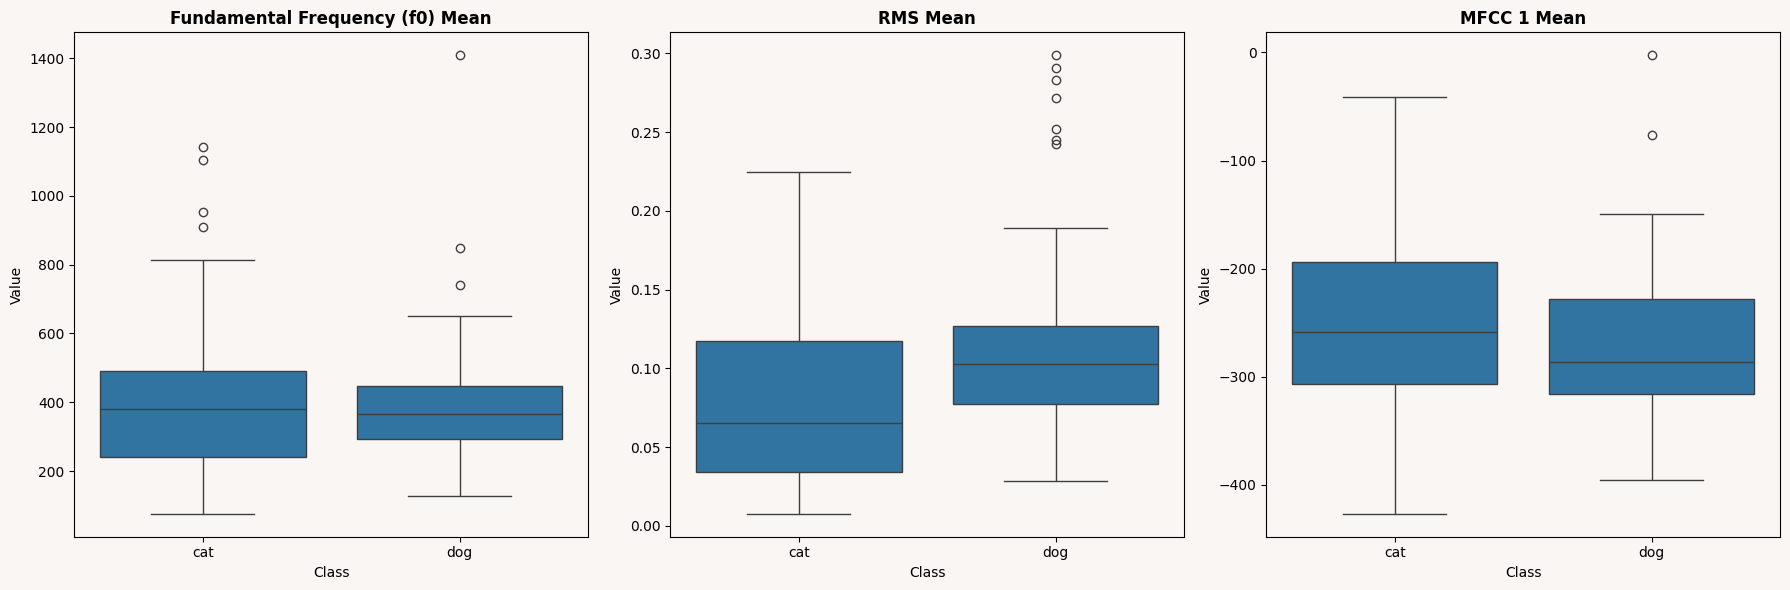

In [19]:
features = ['f0_mean', 'rms_mean', 'mfcc_1_mean']
plot_titles = ['Fundamental Frequency (f0) Mean', 'RMS Mean', 'MFCC 1 Mean']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor('#F9F6F3')

for ax, feature, title in zip(axes, features, plot_titles):
    sns.boxplot(data=features_df, x='class_name', y=feature, ax=ax)

    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Class')
    ax.set_ylabel('Value')
    ax.set_facecolor('#F9F6F3')

plt.tight_layout()
plt.show()

**Intensitas suara anjing relatif lebih tinggi; MFCC anjing relatif lebih rendah, menunjukkan adanya perbedaan suara anjing dan kucing dari saluran vokalnya.**

In [20]:
eda_features = ['f0_mean', 'rms_mean', 'mfcc_1_mean']

summary_stats = features_df.groupby('class_name')[eda_features].agg(['mean', 'median'])

print(summary_stats)

               f0_mean              rms_mean          mfcc_1_mean            
                  mean      median      mean   median        mean      median
class_name                                                                   
cat         400.037041  379.407455  0.078472  0.06543 -252.841814 -258.519653
dog         398.444145  364.849368  0.116443  0.10304 -273.849848 -286.066818


# 3b. Feature Importance

Feature importance dilakukan dengan cara melihat seberapa penting fitur dalam klasifikasi menggunakan random forest. Hasil feature importance kemudian dilakukan pengujian Mann-Whitney untuk menguji apakah ada perbedaan secara statistic antara nilai fitur akustik suara kucing dengan anjing; fitur dengan nilai p-value < 0.05 dianggap signifikan dalam membedakan kelas. Kemudian dilakukan uji kolinearitas untuk membuang fitur-fitur yang berkorelasi atau mendeskripsikan informasi yang sama; digunakan untuk memperkecil dimensi data dan mencegah overfitting.

In [21]:
feature_columns = features_df.select_dtypes(include=np.number).columns.tolist()

In [22]:
def get_feature_groups(columns):
    columns = list(columns)

    time_cols = [
        c for c in columns
        if c.startswith((
            "rms_", "zcr_", "peak_",
            "crest_", "ste_", "envelope_",
            "amplitude_"
        ))
    ]

    spectral_cols = [
        c for c in columns
        if c.startswith((
            "spectral_", "dominant_frequency_", "f0_"
        ))
    ]

    mfcc_cols = [
        c for c in columns
        if c.startswith((
            "mfcc_", "delta_mfcc_", "delta2_mfcc_"
        ))
    ]

    return {
        "Time": time_cols,
        "Spectral": spectral_cols,
        "MFCC": mfcc_cols,
        "Time+Spectral": time_cols + spectral_cols,
        "Spectral+MFCC": spectral_cols + mfcc_cols,
        "All": columns
    }


FEATURE_GROUPS = get_feature_groups(feature_columns)

for name, cols in FEATURE_GROUPS.items():
    print(f"{name:16s}: {len(cols)} features")


Time            : 18 features
Spectral        : 46 features
MFCC            : 90 features
Time+Spectral   : 64 features
Spectral+MFCC   : 136 features
All             : 154 features


In [23]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

X = features_df.drop(columns=['class_name', 'file_path', 'split', 'label'], errors='ignore')
y = features_df['class_name']

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(skf.split(X, y))

def make_rf():
    return RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

def evaluate_folds(X, y, folds, model_factory, feature_subset, verbose=False):
    X_subset = X[feature_subset]

    accuracies = []
    f1_macros = []

    for fold_idx, (train_idx, val_idx) in enumerate(folds):
        X_train, X_val = X_subset.iloc[train_idx], X_subset.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model = model_factory()
        model.fit(X_train, y_train)

        y_pred = model.predict(X_val)

        accuracies.append(accuracy_score(y_val, y_pred))
        f1_macros.append(f1_score(y_val, y_pred, average='macro'))

    summary = {
        "accuracy_mean": float(np.mean(accuracies)),
        "accuracy_std": float(np.std(accuracies)),
        "f1_macro_mean": float(np.mean(f1_macros)),
        "f1_macro_std": float(np.std(f1_macros))
    }

    fold_df = pd.DataFrame({"accuracy": accuracies, "f1_macro": f1_macros})

    return fold_df, summary, None

In [36]:
def run_ablation_study(X, y, folds):
    rows = []

    for group_name, cols in FEATURE_GROUPS.items():

        fold_df, summary, _ = evaluate_folds(
            X=X,
            y=y,
            folds=folds,
            model_factory=make_rf,
            feature_subset=cols,
            verbose=False
        )

        rows.append({
            "feature_group": group_name,
            "n_features": len(cols),
            "accuracy_mean": summary["accuracy_mean"],
            "accuracy_std": summary["accuracy_std"],
            "f1_macro_mean": summary["f1_macro_mean"],
            "f1_macro_std": summary["f1_macro_std"]
        })

    return (
        pd.DataFrame(rows)
        .sort_values("f1_macro_mean", ascending=False)
        .reset_index(drop=True)
    )


ablation_results = run_ablation_study(X, y, folds)
display(ablation_results)

,feature_group,n_features,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std
0,Spectral+MFCC,136,0.933016,0.013362,0.924653,0.015301
1,All,154,0.933016,0.013362,0.924653,0.015301
2,MFCC,90,0.927302,0.022479,0.918514,0.025509
3,Time+Spectral,64,0.882857,0.044096,0.866518,0.049440
4,Spectral,46,0.877302,0.048058,0.858593,0.056954
5,Time,18,0.854921,0.040323,0.836073,0.041329


In [25]:
from scipy.stats import mannwhitneyu

cat_data = features_df[features_df['class_name'] == 'cat']
dog_data = features_df[features_df['class_name'] == 'dog']

numeric_cols = features_df.select_dtypes(include=np.number).columns.tolist()

mw_results = []
for col in numeric_cols:
    stat, p_value = mannwhitneyu(cat_data[col], dog_data[col], alternative='two-sided')
    mw_results.append({'feature': col, 'p_value': p_value})

mw_df = pd.DataFrame(mw_results)

significant_features = mw_df[mw_df['p_value'] < 0.05].sort_values('p_value')
print(f"Statistically significant features: {len(significant_features)} out of {len(numeric_cols)}")

sig_feature_names = significant_features['feature'].tolist()
X_significant = features_df[sig_feature_names]

corr_matrix = X_significant.corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

collinear_threshold = 0.85
to_drop = [column for column in upper.columns if any(upper[column] > collinear_threshold)]

final_features = [feat for feat in sig_feature_names if feat not in to_drop]

print(f"Features dropped due to high collinearity: {len(to_drop)}")
print(f"Final selected features: {len(final_features)}")
print("\nTop 10 Final Features:")
print(final_features[:10])

Statistically significant features: 97 out of 154
Features dropped due to high collinearity: 20
Final selected features: 77

Top 10 Final Features:
['mfcc_4_mean', 'spectral_rolloff_mean', 'zcr_max', 'delta_mfcc_1_mean', 'spectral_centroid_max', 'zcr_std', 'spectral_flatness_max', 'spectral_flatness_mean', 'dominant_frequency_std', 'spectral_contrast_2_mean']


# 3. Building Models

# **Jawaban No C**

In [26]:
'''
Gini impurity meminimalkan probabilitas salah klasifikasi kelas, entropy memaksimalkan pemisahan informasi antar kelas kucing dan anjing.
Max depth yang tidak terbatas memiliki resiko overfitting dan max depth makin kecil memaksa model untuk menyimpulkan pola hanya dari fitur-fitur dominan.
Min samples split yang tinggi mencegah pohon membuat percabangan hanya untuk mengklasifikasi satu atau dua anomali.
Min samples leaf menentukan jumlah minimum sampel yang harus ada di setiap node leaf.  Min samples leaf yang tinggi membuat decision boundary menjadi lebih halus dan
mencegah terbentuknya daun unik untuk setiap sampel training individual sehingga model tidak hancur ketika diberikan data test.
'''

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

X_train_optimized = features_df[final_features]
y_train = features_df['class_name']

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 6]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)

grid_search_dt = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid_dt,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Hyperparameter Tuning...")
grid_search_dt.fit(X_train_optimized, y_train)

best_dt = grid_search_dt.best_estimator_

print("\n--- Decision Tree Tuning Results ---")
print(f"Best Hyperparameters: {grid_search_dt.best_params_}")
print(f"Best Cross-Validation Macro-F1 Score: {grid_search_dt.best_score_:.4f}")

Hyperparameter Tuning...
Fitting 5 folds for each of 120 candidates, totalling 600 fits

--- Decision Tree Tuning Results ---
Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 6, 'min_samples_split': 2}
Best Cross-Validation Macro-F1 Score: 0.8738


In [35]:
'''
n_estimator menentukan total jumlah pohon keputusan yang akan dibangun di dalam ensemble.
Semakin banyak pohon akan meningkatkan stabilitas model dan menurunkan resiko overfit.
max_features mengatur jumlah maksimal fitur yang ditarik secara acak saat mencari percabangan terbaik pada setiap node.
Hal ini mencegah satu fitur dominan menguasai seluruh ensemble.
max_depth membatasi kedalaman maksimal tiap pohon di RF, hal ini mencegah model overfit.
min samples split yang tinggi mencegah pohon membuat percabangan hanya untuk mengklasifikasi satu atau dua anomali.
'''

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)

grid_search_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Hyperparameter Tuning...")
grid_search_rf.fit(X_train_optimized, y_train)

best_rf = grid_search_rf.best_estimator_

print("\n--- Random Forest Tuning Results ---")
print(f"Best Hyperparameters: {grid_search_rf.best_params_}")
print(f"Best Cross-Validation Macro-F1 Score: {grid_search_rf.best_score_:.4f}")

Hyperparameter Tuning...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

--- Random Forest Tuning Results ---
Best Hyperparameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation Macro-F1 Score: 0.9313


In [34]:
'''
logreg penalty menentukan jenis regularisasi, bisa jadi salah satu lebih bagus.
logreg C mengatur seberapa besar regularisasi, untuk mencegah overfitting.
Lorgreg solver digunakan untuk menghitung weight model.
logreg max iter digunakan untuk menentukan jumlah penghitungan sebelum model konvergen.
'''

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state=42))
])

param_grid_lr = {
    'logreg__penalty': ['l1', 'l2'],
    'logreg__C': [0.01, 0.1, 1, 10, 100],
    'logreg__solver': ['liblinear'],
    'logreg__max_iter': [1000, 2000]
}

grid_search_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Hyperparameter Tuning...")
grid_search_lr.fit(X_train_optimized, y_train)

best_lr = grid_search_lr.best_estimator_

print("\n--- Logistic Regression Tuning Results ---")
print(f"Best Hyperparameters: {grid_search_lr.best_params_}")
print(f"Best Cross-Validation Macro-F1 Score: {grid_search_lr.best_score_:.4f}")

Hyperparameter Tuning...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

--- Logistic Regression Tuning Results ---
Best Hyperparameters: {'logreg__C': 1, 'logreg__max_iter': 1000, 'logreg__penalty': 'l2', 'logreg__solver': 'liblinear'}
Best Cross-Validation Macro-F1 Score: 0.9393


# 4. Evaluating Models

# **Jawaban No D**

# Kesimpulan
Setiap model mampu mengklasifikasikan data test dengan baik. Hipotesis saya mengapa ada beberapa sampel anjing yang diklasifikasikan sebagai kucing adalah karena data train kucing lebih banyak sehingga model sedikit bias ke kucing.
Tidak ada alasan di balik mengapa salah satu model lebih baik daripada yang lainnya. Performa semuanya sangat mirip.
Tidak ada alasan di balik mengapa salah satu model lebih baik daripada yang lainnya. Performa semuanya sangat mirip.

In [42]:
test_df = meta[meta['split'] == 'test']

extracted_test_data = []

print("Extracting test features...")
for index, row in tqdm(test_df.iterrows(), total=test_df.shape[0]):
    file_path = row['file_path']

    try:
        feats = extract_all_features(file_path)

        feats['class_name'] = row['class_name']

        extracted_test_data.append(feats)
    except Exception as e:
        print(f"Error processing {file_path}: {e}")

test_features_df = pd.DataFrame(extracted_test_data)

test_features_df.to_csv('extracted_audio_features_test.csv', index=False)

Extracting test features...


100%|██████████| 98/98 [00:08<00:00, 10.89it/s]



=== Decision Tree Classification Report ===
              precision    recall  f1-score   support

         cat       0.80      0.98      0.88        49
         dog       0.97      0.76      0.85        49

    accuracy                           0.87        98
   macro avg       0.89      0.87      0.87        98
weighted avg       0.89      0.87      0.87        98


=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

         cat       0.82      1.00      0.90        49
         dog       1.00      0.78      0.87        49

    accuracy                           0.89        98
   macro avg       0.91      0.89      0.89        98
weighted avg       0.91      0.89      0.89        98


=== Random Forest Classification Report ===
              precision    recall  f1-score   support

         cat       0.82      1.00      0.90        49
         dog       1.00      0.78      0.87        49

    accuracy                           0.

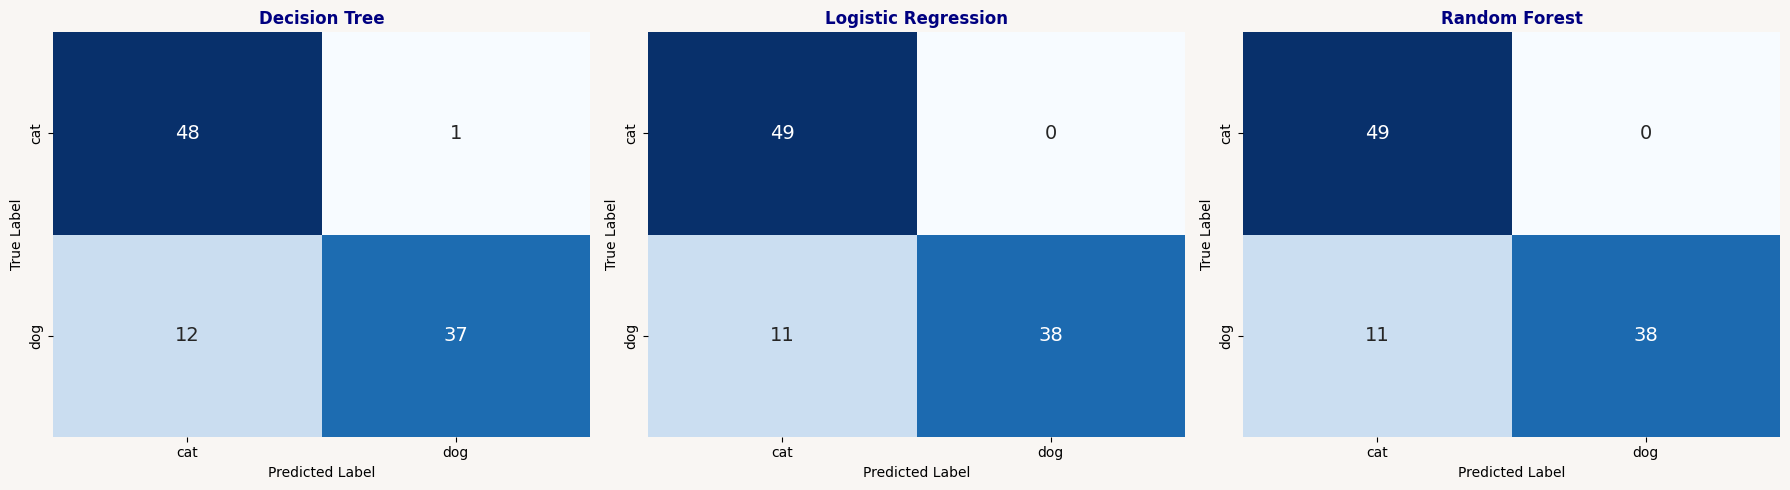

In [32]:
from sklearn.metrics import confusion_matrix, classification_report

X_test = test_features_df[final_features]
y_test = test_features_df['class_name']

models = {
    "Decision Tree": best_dt,
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.patch.set_facecolor('#F9F6F3')

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    print(f"\n=== {name} Classification Report ===")
    print(classification_report(y_test, y_pred, target_names=['cat', 'dog']))

    cm = confusion_matrix(y_test, y_pred, labels=['cat', 'dog'])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['cat', 'dog'], yticklabels=['cat', 'dog'],
                cbar=False, annot_kws={"size": 14})

    ax.set_title(name, fontweight='bold', color='navy')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_facecolor('#F9F6F3')

plt.tight_layout()
plt.show()

In [40]:
test_df_aligned = test_df.reset_index(drop=True)
error_analysis_df = test_features_df.reset_index(drop=True).copy()

error_analysis_df['file_path'] = test_df_aligned['file_path']

error_analysis_df['predicted_class'] = best_lr.predict(X_test)

misclassified_samples = error_analysis_df[error_analysis_df['class_name'] != error_analysis_df['predicted_class']]

print(len(misclassified_samples))
display(misclassified_samples[['file_path', 'class_name', 'predicted_class']])

11


,file_path,class_name,predicted_class
55,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
57,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
60,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
68,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
73,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
76,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
79,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
86,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
88,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat
91,/content/extracted_data/cats_dogs/dog_barking_...,dog,cat


In [41]:
for index, row in misclassified_samples.iterrows():
    print(f"File: {row['file_path']}")
    print(f"True Label: {row['class_name']} | Predicted: {row['predicted_class']}")

    ipd.display(ipd.Audio(row['file_path']))

    print("-" * 50)

# audio paling atas adalah anomali karena ada suara anjing dan kucing

File: /content/extracted_data/cats_dogs/dog_barking_106.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_94.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_100.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_8.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_96.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_3.wav
True Label: dog | Predicted: cat


... (2 outputs left out)

--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_11.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_112.wav
True Label: dog | Predicted: cat


--------------------------------------------------
File: /content/extracted_data/cats_dogs/dog_barking_109.wav
True Label: dog | Predicted: cat


--------------------------------------------------
